# Session 15 · Model Interpretability and Interoperability

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-15-model-interpretability.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: exact Shapley values by hand

In [1]:
"""Exact Shapley values for a tiny model by enumerating every coalition, and checking additivity."""
from itertools import combinations
from math import factorial
import numpy as np

# A loan score model with an interaction: f = 10 + 3*income + 2*history + 4*income*history - 5*debt
features = ["income", "history", "debt"]
x = {"income": 1.0, "history": 1.0, "debt": 0.5}          # the applicant (scaled values)
baseline = {"income": 0.2, "history": 0.4, "debt": 0.3}   # an 'average' applicant (background)

def f(v):
    return 10 + 3 * v["income"] + 2 * v["history"] + 4 * v["income"] * v["history"] - 5 * v["debt"]

def value(coalition):
    """Prediction when features in the coalition take the applicant's values, others the baseline."""
    v = {k: (x[k] if k in coalition else baseline[k]) for k in features}
    return f(v)

n = len(features)
phi = {}
for i in features:
    others = [k for k in features if k != i]
    total = 0.0
    for size in range(n):
        for S in combinations(others, size):
            weight = factorial(len(S)) * factorial(n - len(S) - 1) / factorial(n)
            total += weight * (value(set(S) | {i}) - value(set(S)))
    phi[i] = total

base, pred = value(set()), value(set(features))
print(f"base value f(baseline) = {base:.3f}   prediction f(x) = {pred:.3f}   difference = {pred - base:.3f}")
for k, v in phi.items():
    print(f"  SHAP value of {k:<8} = {v:+.3f}")
print(f"sum of SHAP values = {sum(phi.values()):.3f}  (equals the difference: additivity holds)")

base value f(baseline) = 10.220   prediction f(x) = 16.500   difference = 6.280
  SHAP value of income   = +4.640
  SHAP value of history  = +2.640
  SHAP value of debt     = -1.000
sum of SHAP values = 6.280  (equals the difference: additivity holds)


### Example 2 · Intermediate: permutation importance and partial dependence

test R2: 0.927



permutation importance (drop in R2 when shuffled):
  area_sqft     1.096 ± 0.035
  distance_km   0.636 ± 0.030
  age_years     0.155 ± 0.006
  floor         0.057 ± 0.004
  random_noise  0.000 ± 0.001


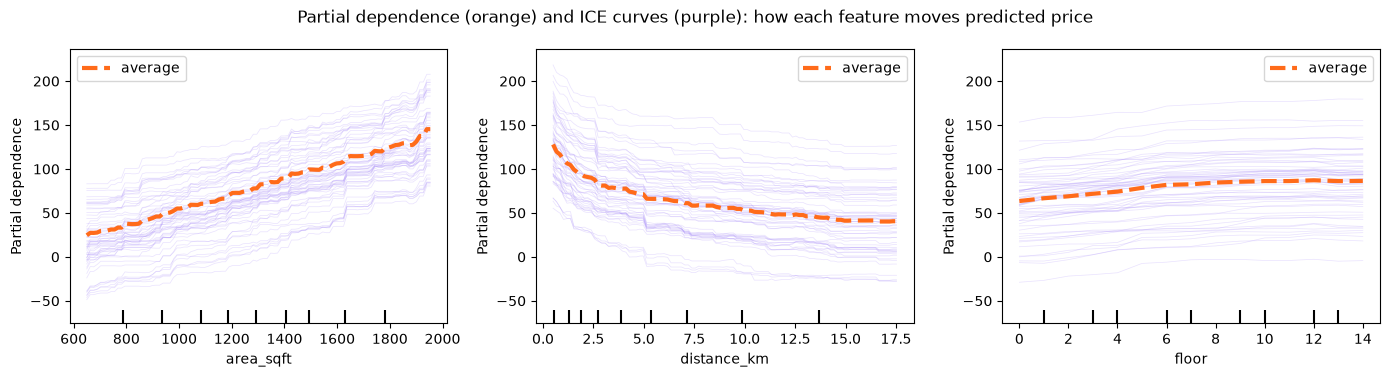

In [2]:
"""Global explanations for a gradient-boosting model: permutation importance and partial dependence plots."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

rng = np.random.default_rng(0)
n = 3000
X = pd.DataFrame({"area_sqft": rng.normal(1300, 400, n).clip(400, 3500), "age_years": rng.integers(0, 40, n),
                  "distance_km": rng.exponential(6, n).clip(0.5, 30), "floor": rng.integers(0, 15, n),
                  "random_noise": rng.normal(0, 1, n)}).astype(float)    # float dtypes for partial dependence
y = (0.09 * X.area_sqft - 1.2 * X.age_years - 25 * np.log(X.distance_km) + 3 * np.minimum(X.floor, 8)
     + rng.normal(0, 12, n))                                   # price in lakh (synthetic)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=0)
model = HistGradientBoostingRegressor(random_state=0).fit(X_tr, y_tr)
print(f"test R2: {model.score(X_te, y_te):.3f}")

imp = permutation_importance(model, X_te, y_te, n_repeats=10, random_state=0, scoring="r2")
order = imp.importances_mean.argsort()[::-1]
print("\npermutation importance (drop in R2 when shuffled):")
for j in order:
    print(f"  {X.columns[j]:<13} {imp.importances_mean[j]:.3f} ± {imp.importances_std[j]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
PartialDependenceDisplay.from_estimator(model, X_te, ["area_sqft", "distance_km", "floor"], kind="both",
                                        subsample=60, random_state=0, ax=ax,
                                        ice_lines_kw={"color": "#A78BFA", "alpha": .25}, pd_line_kw={"color": "#FF6B1A", "lw": 3})
fig.suptitle("Partial dependence (orange) and ICE curves (purple): how each feature moves predicted price")
fig.tight_layout(); fig.savefig("session-15_partial_dependence.png", dpi=100); plt.show()

### Example 3 · Intermediate: SHAP with TreeExplainer (local and global)

test accuracy: 0.788

applicant #444: P(approve) = 0.011
base value (log-odds) -1.010 + sum of SHAP -3.527 = -4.536 | model log-odds -4.536
  credit_score    =    443.0   SHAP -1.829  (pushes towards reject)
  debt_ratio      =    0.728   SHAP -1.638  (pushes towards reject)
  years_employed  =     13.9   SHAP +0.435  (pushes towards approve)
  income_k        =     49.0   SHAP -0.321  (pushes towards reject)
  late_payments   =      1.0   SHAP -0.173  (pushes towards reject)

global importance (mean |SHAP|):
 credit_score      0.755
debt_ratio        0.721
late_payments     0.424
income_k          0.385
years_employed    0.324


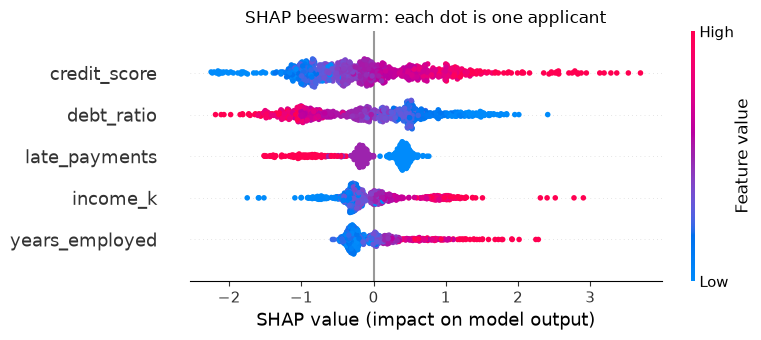

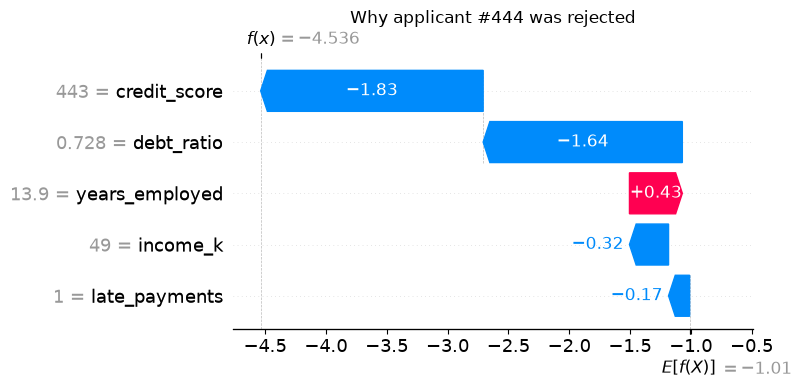

In [3]:
"""SHAP values for a gradient-boosting classifier: additivity check, one explained prediction, global ranking, beeswarm."""
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
warnings.filterwarnings("ignore")

rng = np.random.default_rng(1)
n = 3000
X = pd.DataFrame({"income_k": rng.lognormal(4.2, .4, n).round(), "credit_score": rng.normal(650, 70, n).round(),
                  "debt_ratio": rng.beta(2, 5, n).round(3), "late_payments": rng.poisson(.7, n),
                  "years_employed": rng.exponential(5, n).round(1)})
z = -1 + .02 * (X.income_k - 70) + .015 * (X.credit_score - 650) - 6 * (X.debt_ratio - .3) - .8 * X.late_payments + .08 * X.years_employed
y = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)                           # 1 = loan approved
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=0)
model = GradientBoostingClassifier(random_state=0).fit(X_tr, y_tr)
print(f"test accuracy: {model.score(X_te, y_te):.3f}")

explainer = shap.TreeExplainer(model)
sv = explainer(X_te)                       # values are in log-odds for this model
base = float(np.ravel(explainer.expected_value)[0])
i = int(np.argmin(model.predict_proba(X_te)[:, 1]))                    # the most strongly rejected applicant
row = sv[i]
logit = model.decision_function(X_te.iloc[[i]])[0]
print(f"\napplicant #{i}: P(approve) = {model.predict_proba(X_te.iloc[[i]])[0, 1]:.3f}")
print(f"base value (log-odds) {base:.3f} + sum of SHAP {row.values.sum():.3f} = {base + row.values.sum():.3f} | model log-odds {logit:.3f}")
for name, val, v in sorted(zip(X.columns, X_te.iloc[i], row.values), key=lambda t: -abs(t[2])):
    print(f"  {name:<15} = {val:>8}   SHAP {v:+.3f}  ({'pushes towards approve' if v > 0 else 'pushes towards reject'})")

mean_abs = pd.Series(np.abs(sv.values).mean(0), index=X.columns).sort_values(ascending=False)
print("\nglobal importance (mean |SHAP|):\n", mean_abs.round(3).to_string())

shap.plots.beeswarm(sv, show=False)
plt.title("SHAP beeswarm: each dot is one applicant"); plt.tight_layout()
plt.savefig("session-15_shap_beeswarm.png", dpi=100, bbox_inches="tight"); plt.show(); plt.close("all")
shap.plots.waterfall(row, show=False)
plt.title(f"Why applicant #{i} was rejected"); plt.tight_layout()
plt.savefig("session-15_shap_waterfall.png", dpi=100, bbox_inches="tight"); plt.show()

### Example 4 · Advanced: LIME for the same applicant, compared with SHAP

In [4]:
"""LIME explanation of one prediction from a random forest, its stability across runs, and agreement with SHAP."""
import warnings
import numpy as np
import pandas as pd
import shap
from lime.lime_tabular import LimeTabularExplainer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
warnings.filterwarnings("ignore")

rng = np.random.default_rng(1)
n = 3000
X = pd.DataFrame({"income_k": rng.lognormal(4.2, .4, n).round(), "credit_score": rng.normal(650, 70, n).round(),
                  "debt_ratio": rng.beta(2, 5, n).round(3), "late_payments": rng.poisson(.7, n),
                  "years_employed": rng.exponential(5, n).round(1)})
z = -1 + .02 * (X.income_k - 70) + .015 * (X.credit_score - 650) - 6 * (X.debt_ratio - .3) - .8 * X.late_payments + .08 * X.years_employed
y = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=0)
rf = RandomForestClassifier(300, min_samples_leaf=5, random_state=0, n_jobs=-1).fit(X_tr, y_tr)

applicant = X_te.iloc[0]
print("applicant:", applicant.to_dict())
print(f"random forest P(approve) = {rf.predict_proba(applicant.to_frame().T)[0, 1]:.3f}")

lime_exp = LimeTabularExplainer(X_tr.values, feature_names=list(X.columns), class_names=["reject", "approve"],
                                mode="classification", discretize_continuous=True, random_state=0)
exp = lime_exp.explain_instance(applicant.values, rf.predict_proba, num_features=5, num_samples=3000)
print("\nLIME explanation (weight towards 'approve'):")
for rule, w in exp.as_list():
    print(f"  {rule:<32} {w:+.3f}")
print(f"LIME local model R2 (how well the line fits locally): {exp.score:.2f}")

tops = []
for seed in range(5):
    e = LimeTabularExplainer(X_tr.values, feature_names=list(X.columns), mode="classification",
                             random_state=seed).explain_instance(applicant.values, rf.predict_proba, num_features=2, num_samples=1000)
    tops.append(tuple(r.split(" ")[0] if r.split(" ")[0] in X.columns else r.split(" ")[2] for r, _ in e.as_list()))
print("\ntop-2 features over 5 LIME runs with different seeds:", tops)

sv = shap.TreeExplainer(rf)(X_te.iloc[[0]])
vals = sv.values[0, :, 1] if sv.values.ndim == 3 else sv.values[0]
print("SHAP ranking for the same applicant:", list(X.columns[np.argsort(-np.abs(vals))][:3]))

applicant: {'income_k': 118.0, 'credit_score': 537.0, 'debt_ratio': 0.116, 'late_payments': 0.0, 'years_employed': 15.6}
random forest P(approve) = 0.514

LIME explanation (weight towards 'approve'):
  credit_score <= 602.00           -0.238
  debt_ratio <= 0.16               +0.238
  income_k > 87.00                 +0.167
  years_employed > 7.07            +0.125
  late_payments <= 0.00            +0.101
LIME local model R2 (how well the line fits locally): 0.51



top-2 features over 5 LIME runs with different seeds: [('credit_score', 'income_k'), ('credit_score', 'debt_ratio'), ('credit_score', 'debt_ratio'), ('credit_score', 'debt_ratio'), ('debt_ratio', 'credit_score')]
SHAP ranking for the same applicant: ['credit_score', 'income_k', 'years_employed']


### Example 5 · Advanced: interoperability: export to ONNX and run without scikit-learn

In [5]:
"""Export a scikit-learn pipeline to ONNX, run it with ONNX Runtime, check identical predictions, save a model card."""
import json
import numpy as np
import onnxruntime as ort
from skl2onnx import to_onnx
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X, y = load_breast_cancer(return_X_y=True)
X = X.astype(np.float32)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.25, random_state=0, stratify=y)
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)

onx = to_onnx(pipe, X_tr[:1], options={id(pipe[-1]): {"zipmap": False}}, target_opset=17)
with open("tumour_model.onnx", "wb") as fh:
    fh.write(onx.SerializeToString())
print(f"ONNX file size: {len(onx.SerializeToString()) / 1024:.1f} KB | inputs: {[i.name for i in onx.graph.input]} "
      f"| outputs: {[o.name for o in onx.graph.output]}")
print("operators used:", sorted({node.op_type for node in onx.graph.node}))

sess = ort.InferenceSession("tumour_model.onnx", providers=["CPUExecutionProvider"])
labels, probs = sess.run(None, {sess.get_inputs()[0].name: X_te})
same_labels = np.array_equal(labels, pipe.predict(X_te))
max_diff = np.abs(probs - pipe.predict_proba(X_te)).max()
print(f"ONNX Runtime vs scikit-learn: identical labels = {same_labels}, max probability difference = {max_diff:.2e}")

card = {
    "model_name": "tumour-malignancy-logreg", "version": "1.0.0", "format": "ONNX opset 17",
    "intended_use": "decision support for clinicians reviewing biopsy measurements; not a diagnosis",
    "training_data": "Wisconsin breast cancer measurements (569 cases, 30 features)",
    "metrics": {"test_accuracy": round(float((labels == y_te).mean()), 3)},
    "limitations": ["trained on one hospital's data", "not validated on other populations"],
    "owner": "data science team", "explainability": "coefficients and SHAP values available"}
with open("model_card.json", "w") as fh:
    json.dump(card, fh, indent=2)
print("\nmodel card saved:", json.dumps(card)[:160], "...")

ONNX file size: 1.0 KB | inputs: ['X'] | outputs: ['label', 'probabilities']
operators used: ['LinearClassifier', 'Scaler']
ONNX Runtime vs scikit-learn: identical labels = True, max probability difference = 1.79e-07

model card saved: {"model_name": "tumour-malignancy-logreg", "version": "1.0.0", "format": "ONNX opset 17", "intended_use": "decision support for clinicians reviewing biopsy meas ...


### 🏙️ Real-life data problem: explaining credit decisions with reason codes

In [6]:
"""Real-life problem: SHAP reason codes for rejected loan applicants, a fairness check, and ONNX export."""
import warnings
import numpy as np
import pandas as pd
import shap
import onnxruntime as ort
from skl2onnx import to_onnx
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
warnings.filterwarnings("ignore")

rng = np.random.default_rng(8)
n = 5000
df = pd.DataFrame({"income_k": rng.lognormal(4.2, .45, n).round(), "credit_score": rng.normal(640, 75, n).round(),
                   "debt_ratio": rng.beta(2, 5, n).round(3), "late_payments": rng.poisson(.8, n),
                   "years_employed": rng.exponential(5, n).round(1), "existing_loans": rng.poisson(1, n),
                   "gender_female": (rng.random(n) < .4).astype(int)})
# Historical decisions contain a small unfair penalty for women (bias in past data)
z = (-0.8 + .02 * (df.income_k - 70) + .014 * (df.credit_score - 640) - 5 * (df.debt_ratio - .3)
     - .7 * df.late_payments + .07 * df.years_employed - .3 * df.existing_loans - .5 * df.gender_female)
df["approved"] = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
X, y = df.drop(columns="approved"), df["approved"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.3, random_state=0, stratify=y)

model = GradientBoostingClassifier(random_state=0).fit(X_tr, y_tr)
sv = shap.TreeExplainer(model)(X_te)
imp = pd.Series(np.abs(sv.values).mean(0), index=X.columns).sort_values(ascending=False)
print(f"model with gender: test accuracy {model.score(X_te, y_te):.3f}")
print("global importance (mean |SHAP|):", imp.round(3).to_dict())

pred = model.predict(X_te)
rates = pd.Series(pred).groupby(X_te["gender_female"].values).mean()
print(f"\nFAIRNESS CHECK -> approval rate men {rates[0]:.1%} vs women {rates[1]:.1%} "
      f"| mean SHAP of gender for women: {sv.values[X_te.gender_female.values == 1, list(X.columns).index('gender_female')].mean():+.3f}")

# Remove the sensitive attribute and retrain
fair_cols = [c for c in X.columns if c != "gender_female"]
fair = GradientBoostingClassifier(random_state=0).fit(X_tr[fair_cols], y_tr)
pred_f = fair.predict(X_te[fair_cols])
rates_f = pd.Series(pred_f).groupby(X_te["gender_female"].values).mean()
print(f"model without gender: accuracy {fair.score(X_te[fair_cols], y_te):.3f} | approval men {rates_f[0]:.1%} vs women {rates_f[1]:.1%}")

# Reason codes for rejected applicants (from the fair model)
phrases = {"income_k": "income is low for the amount requested", "credit_score": "credit score is below our range",
           "debt_ratio": "existing debt is high compared with income", "late_payments": "recent late payments on record",
           "years_employed": "short employment history", "existing_loans": "several loans already active"}
sv_f = shap.TreeExplainer(fair)(X_te[fair_cols])
rejected = np.where(pred_f == 0)[0][:4]
print("\nREASON CODES (top 3 negative SHAP contributions):")
for r in rejected:
    contrib = pd.Series(sv_f.values[r], index=fair_cols).sort_values()
    reasons = [phrases[c] for c in contrib.index[:3] if contrib[c] < 0]
    print(f"  applicant {X_te.index[r]}: " + "; ".join(reasons))

onx = to_onnx(fair, X_tr[fair_cols].values[:1].astype(np.float32), options={id(fair): {"zipmap": False}}, target_opset=17)
sess = ort.InferenceSession(onx.SerializeToString(), providers=["CPUExecutionProvider"])
onnx_pred = sess.run(None, {sess.get_inputs()[0].name: X_te[fair_cols].values.astype(np.float32)})[0]
print(f"\nONNX export of the fair model agrees with scikit-learn on {np.mean(onnx_pred == pred_f):.1%} of test applicants")

model with gender: test accuracy 0.797
global importance (mean |SHAP|): {'credit_score': 0.709, 'debt_ratio': 0.579, 'income_k': 0.525, 'late_payments': 0.313, 'gender_female': 0.213, 'existing_loans': 0.197, 'years_employed': 0.176}

FAIRNESS CHECK -> approval rate men 23.8% vs women 13.7% | mean SHAP of gender for women: -0.266


model without gender: accuracy 0.794 | approval men 20.4% vs women 17.9%

REASON CODES (top 3 negative SHAP contributions):
  applicant 2271: credit score is below our range; income is low for the amount requested; short employment history
  applicant 3828: several loans already active; credit score is below our range; short employment history
  applicant 1725: short employment history
  applicant 3820: several loans already active; short employment history; recent late payments on record

ONNX export of the fair model agrees with scikit-learn on 100.0% of test applicants


### 🧩 Mini project: an "explain my prediction" tool for house prices

In [7]:
"""Mini project: a reusable explain() function that prints a plain-language SHAP explanation for any house."""
import warnings
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")

rng = np.random.default_rng(3)
n = 2500
houses = pd.DataFrame({"area_sqft": rng.normal(1400, 450, n).clip(400, 4000).round(), "bedrooms": rng.integers(1, 6, n),
                       "age_years": rng.integers(0, 45, n), "distance_to_centre_km": rng.exponential(7, n).clip(.5, 35).round(1),
                       "has_parking": rng.integers(0, 2, n), "corner_plot": (rng.random(n) < .15).astype(int)})
price = (0.085 * houses.area_sqft + 6 * houses.bedrooms - 0.9 * houses.age_years - 22 * np.log(houses.distance_to_centre_km)
         + 12 * houses.has_parking + 9 * houses.corner_plot + 80 + rng.normal(0, 10, n))
X_tr, X_te, y_tr, y_te = train_test_split(houses, price, test_size=.2, random_state=0)
model = RandomForestRegressor(300, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(X_tr, y_tr)
explainer = shap.TreeExplainer(model)
print(f"model R2 on test houses: {model.score(X_te, y_te):.3f}")

def explain(house: pd.DataFrame, top=4):
    sv = explainer(house)
    base = float(np.ravel(explainer.expected_value)[0]); pred = model.predict(house)[0]
    contrib = pd.Series(sv.values[0], index=house.columns).sort_values(key=np.abs, ascending=False)
    print(f"\nEstimated price: Rs {pred:.1f} lakh (average house: Rs {base:.1f} lakh)")
    for feat in contrib.index[:top]:
        v = contrib[feat]
        print(f"  {'+' if v > 0 else '-'} Rs {abs(v):5.1f} lakh because {feat.replace('_', ' ')} = {house.iloc[0][feat]}")
    print(f"  (all contributions sum to {contrib.sum():+.1f}; base + sum = {base + contrib.sum():.1f})")

explain(pd.DataFrame([{"area_sqft": 2400, "bedrooms": 4, "age_years": 3, "distance_to_centre_km": 2.5, "has_parking": 1, "corner_plot": 1}]))
explain(pd.DataFrame([{"area_sqft": 800, "bedrooms": 2, "age_years": 35, "distance_to_centre_km": 25.0, "has_parking": 0, "corner_plot": 0}]))

model R2 on test houses: 0.929

Estimated price: Rs 294.6 lakh (average house: Rs 175.0 lakh)
  + Rs  88.3 lakh because area sqft = 2400.0
  + Rs  15.3 lakh because distance to centre km = 2.5
  + Rs  11.5 lakh because age years = 3.0
  + Rs   2.7 lakh because bedrooms = 4.0
  (all contributions sum to +119.6; base + sum = 294.6)

Estimated price: Rs 70.3 lakh (average house: Rs 175.0 lakh)
  - Rs  51.1 lakh because area sqft = 800.0
  - Rs  34.4 lakh because distance to centre km = 25.0
  - Rs  11.2 lakh because age years = 35.0
  - Rs   5.1 lakh because bedrooms = 2.0
  (all contributions sum to -104.7; base + sum = 70.3)
